In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity


In [2]:
# Temukan file CSV dari direktori kerja notebook atau salah satu direktori induknya.
DATA_PATH = next(
    (
        base / "data" / "komdigi_hoaks.csv"
        for base in (Path.cwd(), *Path.cwd().parents)
        if (base / "data" / "komdigi_hoaks.csv").is_file()
    ),
    None,
)
if DATA_PATH is None:
    raise FileNotFoundError(
        "komdigi_hoaks.csv tidak ditemukan. Letakkan file di folder data/ dalam repository."
    )

df = pd.read_csv(DATA_PATH)
text_columns = [column for column in ("title", "excerpt", "body_text") if column in df.columns]
if not text_columns:
    raise ValueError("CSV harus memiliki setidaknya satu kolom teks: title, excerpt, atau body_text.")

df["text"] = df[text_columns].fillna("").astype(str).agg(" ".join, axis=1)
df = df[df["text"].str.strip().ne("")].drop_duplicates(subset="text").reset_index(drop=True)
print(f"File: {DATA_PATH}")
print(f"Jumlah dokumen teks: {len(df):,}")
print(f"Kolom teks yang digunakan: {', '.join(text_columns)}")


File: d:\Kuliah\Kelas\Semester 5\Pembelajaran Mesin\TUGAS\PRAKTIKUM\data\komdigi_hoaks.csv
Jumlah dokumen teks: 4,170
Kolom teks yang digunakan: title, excerpt, body_text


In [3]:
# Tinjau struktur data dan label yang tersedia.
display(df[[column for column in ("title", "category", "published_at") if column in df.columns]].head())
if "category" in df.columns:
    print("Distribusi category:")
    display(df["category"].value_counts(dropna=False).to_frame("jumlah"))
    print(f"Jumlah kelas category: {df['category'].nunique(dropna=False)}")


,title,category,published_at
0,[HOAKS] Tautan Pencairan BSU September 2026 Se...,Klarifikasi Hoaks,2026-09-27 23:03:00
1,[HOAKS] Panas El Nino Berkaitan dengan Gelomba...,Klarifikasi Hoaks,2026-09-27 23:02:00
2,[HOAKS] Susu Bebelac Berbahaya karena Mengandu...,Klarifikasi Hoaks,2026-09-27 23:01:00
3,[HOAKS] Purbaya Informasikan Raffi Ahmad Beli ...,Klarifikasi Hoaks,2026-09-26 23:04:00
4,[HOAKS] Tautan Bantuan Laptop dan Ponsel untuk...,Klarifikasi Hoaks,2026-09-26 23:02:00


Distribusi category:


,jumlah
category,
Klarifikasi Hoaks,4170


Jumlah kelas category: 1


In [4]:
# Karena category pada dataset ini hanya memiliki satu kelas, analisis dilanjutkan
# sebagai clustering tanpa label, bukan klasifikasi hoaks vs. bukan hoaks.
INDONESIAN_STOP_WORDS = {
    "ada", "adalah", "agar", "akan", "anda", "atau", "bagi", "bahwa", "belum",
    "berbagai", "berikut", "bersama", "beredar", "benar", "berisi", "bisa", "dan",
    "dari", "dalam", "dapat", "dengan", "dia", "di", "faktanya", "hingga", "ia",
    "ini", "informasi", "itu", "jadi", "jika", "juga", "karena", "ke", "kepada",
    "ketika", "klaim", "kini", "kita", "lagi", "lebih", "masih", "melalui", "memiliki",
    "menjadi", "menurut", "mengeklaim", "merupakan", "mereka", "namun", "oleh", "pada",
    "para", "penjelasan", "saat", "salah", "sama", "sangat", "sebagai", "secara",
    "sebuah", "sehingga", "seperti", "serta", "sudah", "tahun", "tentang", "terhadap",
    "tersebut", "tidak", "unggahan", "untuk", "yang", "hoaks",
}

def clean_text(text):
    text = re.sub(r"\[hoaks\]", " ", str(text).lower())
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^\w\s]", " ", text, flags=re.UNICODE)
    return re.sub(r"\s+", " ", text).strip()

df["clean_text"] = df["text"].map(clean_text)
print("Contoh teks setelah dibersihkan:")
print(df["clean_text"].iloc[0][:500])


Contoh teks setelah dibersihkan:
tautan pencairan bsu september 2026 sebesar rp600 000 kepala biro humas kementerian ketenagakerjaan kemnaker faried abdurrahman nur yuliono mengatakan belum ada kebijakan terkait penyaluran bsu pada 2026 penjelasan beredar sebuah unggahan berisi tautan dengan narasi yang mengeklaim kementerian ketenagakerjaan kemnaker telah menyalurkan bantuan subsidi upah bsu untuk para pekerja sebesar rp600 000 pada september 2026 faktanya klaim tersebut adalah tidak benar dilansir dari kompas com kepala biro 


In [5]:
# Ubah dokumen menjadi fitur TF-IDF unigram dan bigram.
vectorizer = TfidfVectorizer(
    stop_words=sorted(INDONESIAN_STOP_WORDS),
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    max_features=20_000,
    sublinear_tf=True,
)
X_tfidf = vectorizer.fit_transform(df["clean_text"])
print(f"Ukuran matriks TF-IDF: {X_tfidf.shape[0]:,} dokumen x {X_tfidf.shape[1]:,} fitur")


Ukuran matriks TF-IDF: 4,170 dokumen x 20,000 fitur


In [6]:
# Pilih jumlah cluster dengan skor silhouette tertinggi (uji k=2 sampai k=8).
# Silhouette dihitung pada sampel agar evaluasi tetap ringan.
sample_size = min(2_000, X_tfidf.shape[0])
cluster_scores = {}
best_model = None
best_k = None
best_score = float("-inf")

for n_clusters in range(2, min(9, X_tfidf.shape[0])):
    candidate = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    candidate_labels = candidate.fit_predict(X_tfidf)
    score = silhouette_score(
        X_tfidf,
        candidate_labels,
        sample_size=sample_size,
        random_state=42,
    )
    cluster_scores[n_clusters] = score
    print(f"k={n_clusters}: silhouette={score:.4f}")
    if score > best_score:
        best_k, best_score, best_model = n_clusters, score, candidate

if best_model is None:
    raise ValueError("Clustering membutuhkan setidaknya tiga dokumen.")
print(f"\nJumlah cluster terpilih: {best_k} (silhouette={best_score:.4f})")
if best_score < 0.05:
    print("Catatan: skor silhouette rendah; cluster mungkin saling tumpang tindih. Tinjau kata kunci dan contoh dokumen sebelum menarik kesimpulan.")


k=2: silhouette=0.0080
k=3: silhouette=0.0096
k=4: silhouette=0.0101
k=5: silhouette=0.0099
k=6: silhouette=0.0106
k=7: silhouette=0.0108
k=8: silhouette=0.0091

Jumlah cluster terpilih: 7 (silhouette=0.0108)
Catatan: skor silhouette rendah; cluster mungkin saling tumpang tindih. Tinjau kata kunci dan contoh dokumen sebelum menarik kesimpulan.


In [7]:
# Beri nomor cluster pada setiap dokumen dan tinjau ukuran masing-masing cluster.
df["cluster"] = best_model.labels_
cluster_counts = df["cluster"].value_counts().sort_index()
display(cluster_counts.rename("jumlah dokumen").to_frame())

if "category" in df.columns:
    print("Distribusi label sumber per cluster (untuk konteks, bukan target model):")
    display(pd.crosstab(df["cluster"], df["category"]))


,jumlah dokumen
cluster,
0,1439
1,657
2,558
3,358
4,193
5,621
6,344


Distribusi label sumber per cluster (untuk konteks, bukan target model):


category,Klarifikasi Hoaks
cluster,
0,1439
1,657
2,558
3,358
4,193
5,621
6,344


In [8]:
# Tampilkan kata/frasa dengan bobot tertinggi yang menggambarkan tiap cluster.
terms = vectorizer.get_feature_names_out()
for cluster_id, center in enumerate(best_model.cluster_centers_):
    top_indices = center.argsort()[-12:][::-1]
    top_terms = [terms[index] for index in top_indices]
    print(f"Cluster {cluster_id}: {', '.join(top_terms)}")


Cluster 0: video, media, sosial, media sosial, narasi, indonesia, com, dilansir, kategori, kategori link, telah, facebook
Cluster 1: tautan, resmi, bank, situs, akun, undian, mengatasnamakan, bantuan, pendaftaran, berhadiah, program, sosial
Cluster 2: akun whatsapp, whatsapp, akun, mengatasnamakan, whatsapp mengatasnamakan, kabupaten, nomor, penipuan, masyarakat, pesan, foto profil, profil
Cluster 3: ai, video, artificial, artificial intelligence, intelligence, intelligence ai, persen, probabilitas, hasil, moderation, hive, hive moderation
Cluster 4: jokowi, joko, joko widodo, widodo, presiden, widodo jokowi, artikel, ijazah, presiden joko, presiden jokowi, video, berjudul
Cluster 5: prabowo, presiden, presiden prabowo, video, indonesia, prabowo subianto, subianto, dpr, narasi, menteri, purbaya, setelah
Cluster 6: lowongan, tautan, lowongan kerja, kerja, pendaftaran, laman, telegram, pt, mengarah, resmi, rekrutmen, nomor telegram


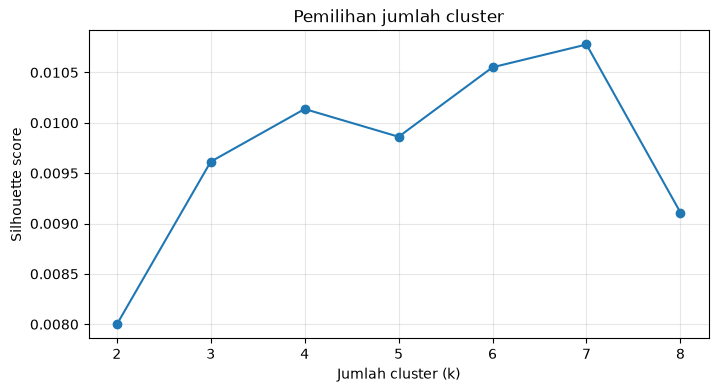

In [9]:
# Bandingkan skor silhouette untuk setiap jumlah cluster yang diuji.
plt.figure(figsize=(8, 4))
plt.plot(list(cluster_scores.keys()), list(cluster_scores.values()), marker="o")
plt.xticks(list(cluster_scores.keys()))
plt.xlabel("Jumlah cluster (k)")
plt.ylabel("Silhouette score")
plt.title("Pemilihan jumlah cluster")
plt.grid(alpha=0.3)
plt.show()


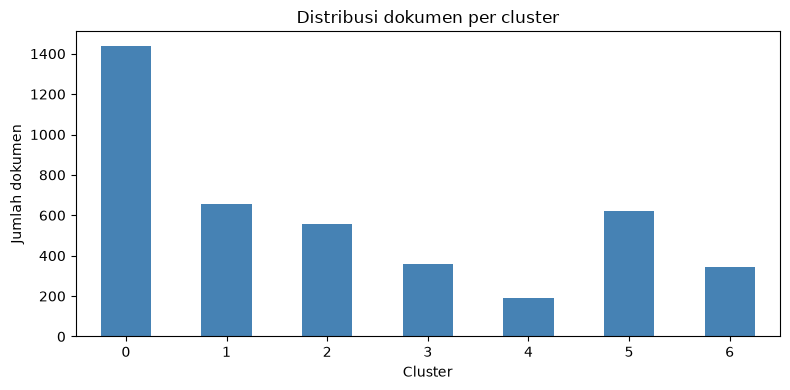

In [10]:
# Visualisasikan banyaknya dokumen pada setiap cluster.
plt.figure(figsize=(8, 4))
cluster_counts.plot(kind="bar", color="steelblue")
plt.xlabel("Cluster")
plt.ylabel("Jumlah dokumen")
plt.title("Distribusi dokumen per cluster")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [11]:
# Tampilkan beberapa judul yang paling dekat dengan pusat masing-masing cluster.
distances = best_model.transform(X_tfidf)
for cluster_id in range(best_k):
    member_indices = (df["cluster"].to_numpy() == cluster_id).nonzero()[0]
    nearest_indices = member_indices[distances[member_indices, cluster_id].argsort()[:3]]
    print(f"\nCluster {cluster_id} - contoh dokumen:")
    for index in nearest_indices:
        title = df.iloc[index].get("title", "(tanpa judul)")
        print(f"- {title}")



Cluster 0 - contoh dokumen:
- [HOAKS] Indonesia dan Amerika Serikat Rasakan Getaran Gempa dan Tsunami Rusia
- [HOAKS] Terjadi KLB Penyakit Difteri di Provinsi DKI Jakarta dan Provinsi Jawa Barat pada Juli 2025
- [HOAKS] Pemain Bulutangkis Cina Meninggal akibat Vaksin Covid-19

Cluster 1 - contoh dokumen:
- [HOAKS] Tautan Undian Berhadiah Bank Jateng November 2025
- [HOAKS] Tautan Undian Berhadiah dari BPD Bali pada November 2025
- [HOAKS] Undian Berhadiah Bank Victoria pada 2024

Cluster 2 - contoh dokumen:
- [HOAKS] Akun WhatsApp Mengatasnamakan Pj Bupati Bulungan Haerumuddin
- [HOAKS] Akun WhatsApp Mengatasnamakan Pj Bupati Hulu Sungai Selatan
- [HOAKS] Akun WhatsApp Mengatasnamakan Pj Bupati Minahasa

Cluster 3 - contoh dokumen:
- [HOAKS] Menteri Purbaya Salurkan Dana Hibah Rp11 Triliun
- [HOAKS] Menkeu Purbaya Beri Dana Bantuan jelang Idul Adha 2026
- [HOAKS] Video TNI Kepung Kapal Malaysia di Kepulauan Seribu

Cluster 4 - contoh dokumen:
- [HOAKS] Kasmujo Tidak Mengakui Presiden 

In [12]:
# Cari dokumen yang paling relevan dengan kata kunci tertentu.
def cari_dokumen(query, top_n=5):
    query_vector = vectorizer.transform([clean_text(query)])
    if query_vector.nnz == 0:
        raise ValueError("Kata kunci tidak memiliki istilah yang dikenal oleh model TF-IDF.")
    similarities = cosine_similarity(query_vector, X_tfidf).ravel()
    top_indices = similarities.argsort()[-top_n:][::-1]
    return df.iloc[top_indices][[column for column in ("title", "cluster") if column in df.columns]].assign(
        kemiripan=similarities[top_indices]
    )

# Contoh pencarian; ganti kata kunci sesuai topik yang ingin ditinjau.
display(cari_dokumen("bantuan sosial", top_n=5))


,title,cluster,kemiripan
2640,[HOAKS] Tautan Bantuan Sosial PKH untuk Ibu Ha...,1,0.252914
3325,[HOAKS] Pemerintah Bagikan Bantuan Sosial Mela...,0,0.230383
2604,[HOAKS] Kemensos Kerja Sama dengan Telegram un...,1,0.204172
3532,[HOAKS] Tautan Pendaftaran Penerima Bansos Pro...,1,0.201901
1269,[HOAKS] Presiden Prabowo akan Mengganti Bantua...,1,0.201740


In [13]:
# Simpan hasil clustering untuk analisis lanjutan.
output_path = DATA_PATH.with_name("komdigi_hoaks_clustered.csv")
df.to_csv(output_path, index=False)
print(f"Hasil clustering disimpan ke: {output_path}")


Hasil clustering disimpan ke: d:\Kuliah\Kelas\Semester 5\Pembelajaran Mesin\TUGAS\PRAKTIKUM\data\komdigi_hoaks_clustered.csv
